# ML Internship Task 1 – Life Expectancy Data Analysis


In [11]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 1. Load the Raw Dataset

The raw dataset is loaded first so that missing values can be analyzed before cleaning.


In [12]:
# Load the raw dataset
df_raw = pd.read_csv("../data/LifeExpectancyData.csv")

# Remove extra spaces from column names
df_raw.columns = df_raw.columns.str.strip()

print("Raw dataset shape:", df_raw.shape)
df_raw.head()


Raw dataset shape: (2938, 22)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


## 2. Missing Values Before Cleaning

The following analysis shows how many values are missing in each column of the raw dataset.


In [13]:
# Missing values before cleaning
missing_before = df_raw.isnull().sum().sort_values(ascending=False)
missing_before = missing_before[missing_before > 0]

print("Missing values before cleaning:")
print(missing_before)


Missing values before cleaning:
Population                         652
Hepatitis B                        553
GDP                                448
Total expenditure                  226
Alcohol                            194
Income composition of resources    167
Schooling                          163
thinness  1-19 years                34
thinness 5-9 years                  34
BMI                                 34
Diphtheria                          19
Polio                               19
Life expectancy                     10
Adult Mortality                     10
dtype: int64


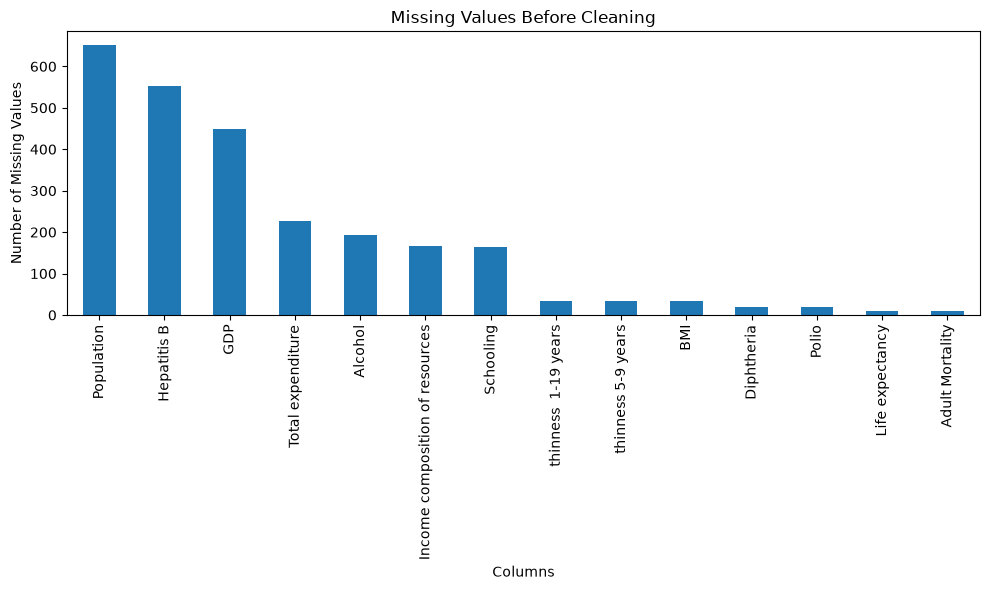

In [14]:
# Visualize missing values before cleaning
plt.figure(figsize=(10, 6))

missing_before.plot(kind="bar")

plt.title("Missing Values Before Cleaning")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()


## 3. Load the Cleaned Dataset

The cleaning process removes rows where `Life expectancy` is missing and fills missing numerical values using country-wise medians, with the overall median used as a fallback when necessary.

The cleaned dataset is then loaded to verify the result.


In [15]:
# Load the cleaned dataset
df = pd.read_csv("../data/cleaned_life_expectancy.csv")

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("Cleaned dataset shape:", df.shape)
df.head()


Cleaned dataset shape: (2928, 22)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [16]:
# Missing values after cleaning
missing_after = df.isnull().sum()

print("Missing values after cleaning:")
print(missing_after)


Missing values after cleaning:
Country                            0
Year                               0
Status                             0
Life expectancy                    0
Adult Mortality                    0
infant deaths                      0
Alcohol                            0
percentage expenditure             0
Hepatitis B                        0
Measles                            0
BMI                                0
under-five deaths                  0
Polio                              0
Total expenditure                  0
Diphtheria                         0
HIV/AIDS                           0
GDP                                0
Population                         0
thinness  1-19 years               0
thinness 5-9 years                 0
Income composition of resources    0
Schooling                          0
dtype: int64


In [17]:
# Visualize missing values after cleaning
missing_after_plot = missing_after[missing_after > 0]

if missing_after_plot.empty:
    print("No missing values remain after cleaning.")
else:
    plt.figure(figsize=(10, 6))
    missing_after_plot.plot(kind="bar")
    plt.title("Missing Values After Cleaning")
    plt.xlabel("Columns")
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


No missing values remain after cleaning.


## 4. Dataset Overview

The cleaned dataset contains the records used for the remaining analysis.


In [18]:
# Show cleaned dataset columns
df.columns


Index(['Country', 'Year', 'Status', 'Life expectancy', 'Adult Mortality',
       'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B',
       'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure',
       'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years',
       'thinness 5-9 years', 'Income composition of resources', 'Schooling'],
      dtype='str')

In [19]:
# Number of rows and columns
df.shape


(2928, 22)

In [20]:
# Show the first rows
df.head()


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


## 5. Life Expectancy Distribution


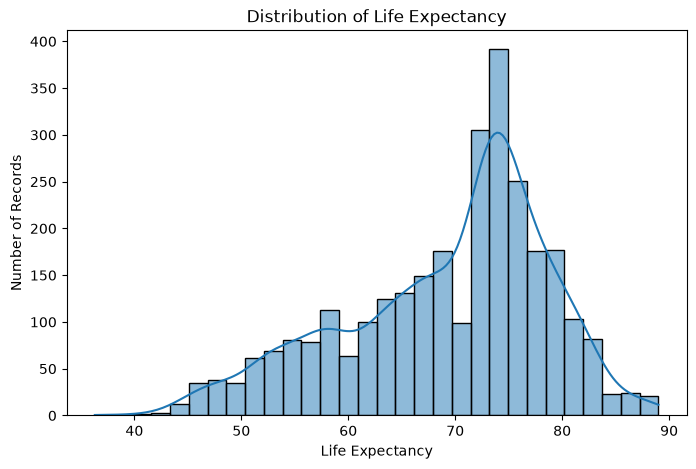

In [21]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Life expectancy"], bins=30, kde=True)

plt.title("Distribution of Life Expectancy")
plt.xlabel("Life Expectancy")
plt.ylabel("Number of Records")

plt.show()


## 6. Life Expectancy by Country Status


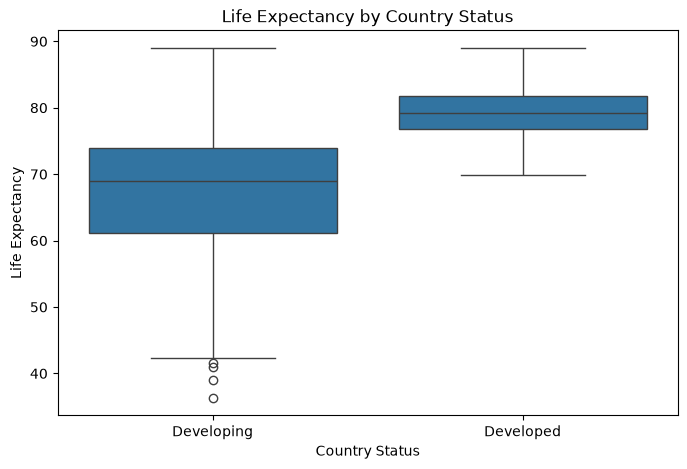

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(x="Status", y="Life expectancy", data=df)

plt.title("Life Expectancy by Country Status")
plt.xlabel("Country Status")
plt.ylabel("Life Expectancy")

plt.show()


## 7. Average Life Expectancy Over the Years


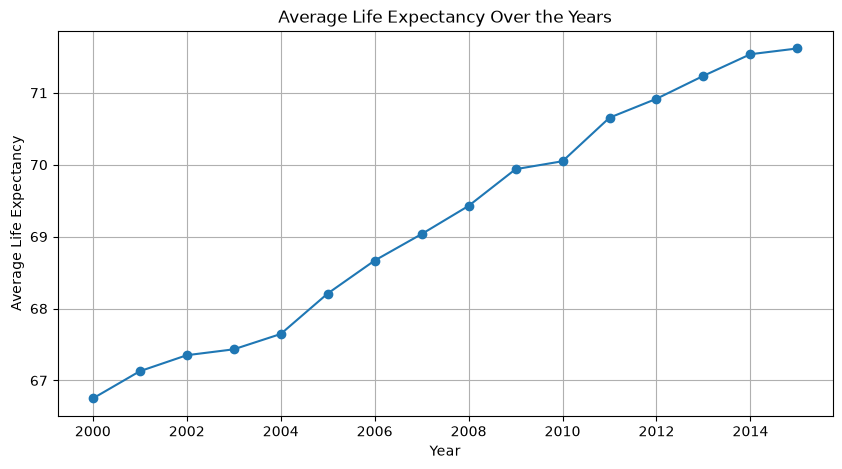

In [23]:
yearly_life_expectancy = df.groupby("Year")["Life expectancy"].mean()

plt.figure(figsize=(10, 5))

plt.plot(
    yearly_life_expectancy.index,
    yearly_life_expectancy.values,
    marker="o"
)

plt.title("Average Life Expectancy Over the Years")
plt.xlabel("Year")
plt.ylabel("Average Life Expectancy")

plt.grid(True)
plt.show()


## 8. Top 10 Countries by Average Life Expectancy


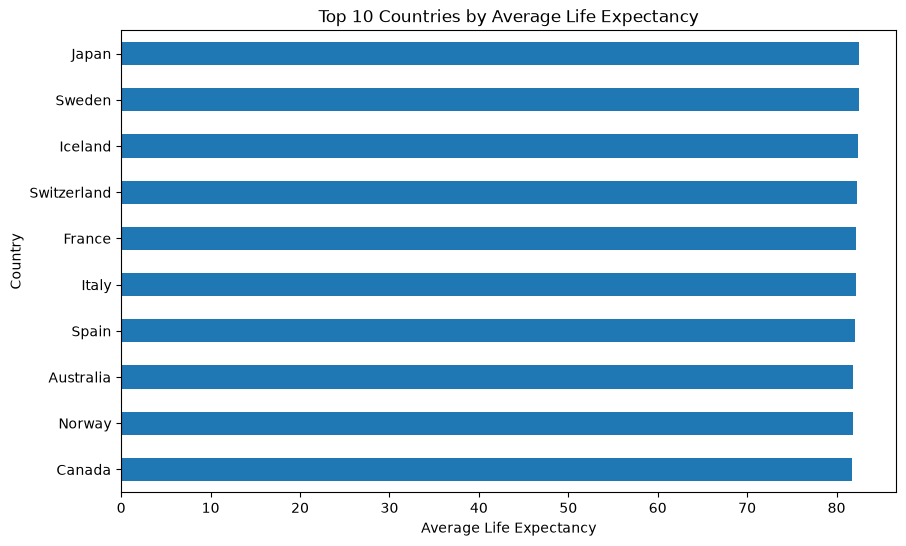

In [24]:
country_life_expectancy = (
    df.groupby("Country")["Life expectancy"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

country_life_expectancy.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Average Life Expectancy")
plt.xlabel("Average Life Expectancy")
plt.ylabel("Country")

plt.show()


# Data Analysis Summary

The Life Expectancy dataset contains information about countries, years, health indicators, economic factors, and life expectancy.

The analysis included:

- Missing-value analysis before cleaning.
- Verification of missing values after cleaning.
- Distribution of Life Expectancy using a histogram.
- Comparison of Life Expectancy by country status using a boxplot.
- Analysis of average Life Expectancy over the years using a line chart.
- Identification of the top 10 countries by average Life Expectancy using a bar chart.

The analysis helps us understand the distribution, differences between categories, missing-value handling, and general patterns in the dataset.
